In [ ]:
import pandas as pd

# If using Colab
from google.colab import files
uploaded = files.upload()

file = list(uploaded.keys())[0]
df = pd.read_csv(file)

df['datetime'] = pd.to_datetime(df['datetime'])

df.head()

Saving hybrid_dataset_FINAL_FIXED.csv to hybrid_dataset_FINAL_FIXED (1).csv


,datetime,co2_proxy,respiration_gCO2,sequestration_gCO2,DO_mgL,NH3_mgL,NO2_mgL,NO3_mgL,pH
0,2026-03-28 18:22:00,818.651072,0.312172,0.003471,5.613185,0.216669,0.053808,1.024245,8.128599
1,2026-03-28 18:26:00,826.443899,0.329743,-0.013323,5.605561,0.209590,0.072267,1.032358,8.126586
2,2026-03-28 18:30:00,836.441124,0.354289,-0.015185,5.629809,0.201883,0.053743,1.034892,8.141049
3,2026-03-28 18:34:00,861.290355,0.372104,-0.000050,5.640076,0.199876,0.056338,1.059451,8.140252
4,2026-03-28 18:38:00,880.204064,0.414855,-0.023913,5.660062,0.196100,0.054600,1.030626,8.128687


In [ ]:
import numpy as np

df['lag1'] = df['co2_proxy'].shift(1)
df['lag3'] = df['co2_proxy'].shift(3)

# Light proxy (important for sequestration)
df['hour'] = df['datetime'].dt.hour
df['light'] = (np.sin(2*np.pi*(df['hour']-6)/24)+1)/2

df['co2_light'] = df['co2_proxy'] * df['light']
df['co2_light_lag'] = df['co2_light'].shift(2)

df = df.dropna()

In [ ]:
split = int(len(df)*0.8)
gap = 12

train = df.iloc[:split-gap].copy()
test  = df.iloc[split:].copy()

print("Train size:", len(train))
print("Test size:", len(test))

Train size: 1704
Test size: 430


In [ ]:
from xgboost import XGBRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

In [ ]:
features_resp = ['co2_proxy','lag1','lag3']

X_train = train[features_resp]
X_test = test[features_resp]

y_train = train['respiration_gCO2']
y_test = test['respiration_gCO2']

# XGBoost
xgb = XGBRegressor(n_estimators=300, max_depth=5)
xgb.fit(X_train, y_train)
pred_xgb = xgb.predict(X_test)

# Random Forest
rf = RandomForestRegressor(n_estimators=200)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)

print("=== RESPIRATION ===")
print("XGB R2:", r2_score(y_test, pred_xgb))
print("RF  R2:", r2_score(y_test, pred_rf))

=== RESPIRATION ===
XGB R2: 0.8395713907679008
RF  R2: 0.8449234301861084


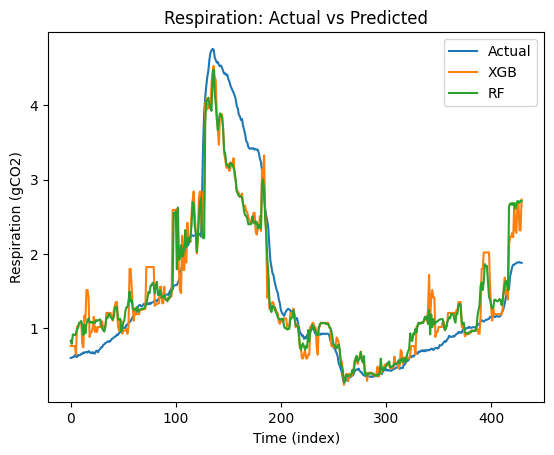

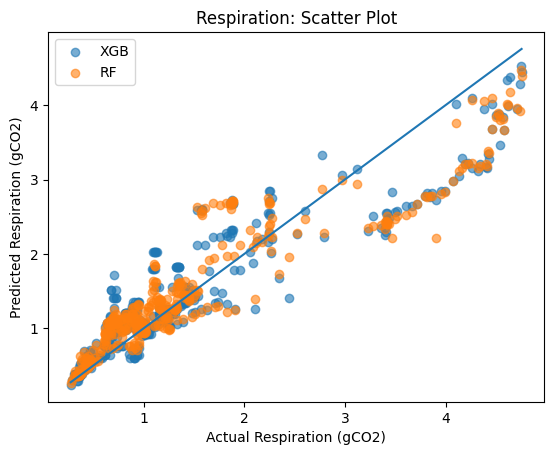

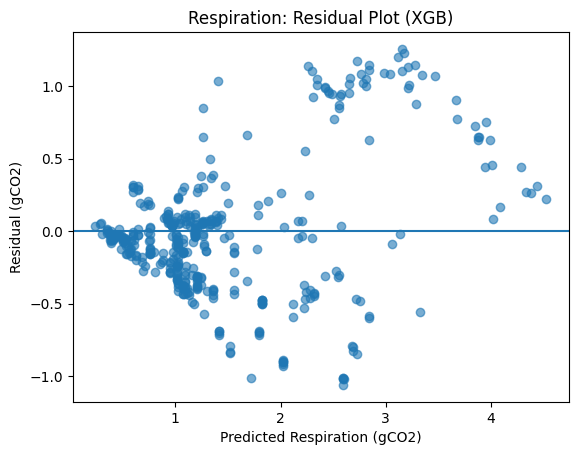

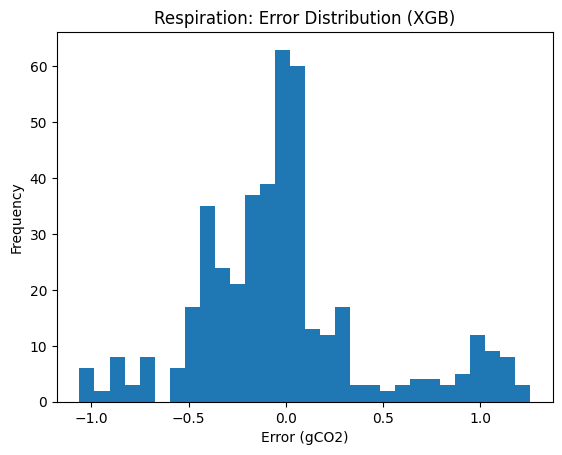

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# ---------- TIME SERIES ----------
plt.figure()
plt.plot(y_test.values, label="Actual")
plt.plot(pred_xgb, label="XGB")
plt.plot(pred_rf, label="RF")
plt.legend()
plt.title("Respiration: Actual vs Predicted")
plt.xlabel("Time (index)")
plt.ylabel("Respiration (gCO2)")
plt.show()


# ---------- SCATTER ----------
plt.figure()
plt.scatter(y_test, pred_xgb, label="XGB", alpha=0.6)
plt.scatter(y_test, pred_rf, label="RF", alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()])
plt.legend()
plt.title("Respiration: Scatter Plot")
plt.xlabel("Actual Respiration (gCO2)")
plt.ylabel("Predicted Respiration (gCO2)")
plt.show()


# ---------- RESIDUAL ----------
res_xgb = y_test - pred_xgb

plt.figure()
plt.scatter(pred_xgb, res_xgb, alpha=0.6)
plt.axhline(0)
plt.title("Respiration: Residual Plot (XGB)")
plt.xlabel("Predicted Respiration (gCO2)")
plt.ylabel("Residual (gCO2)")
plt.show()


# ---------- ERROR DISTRIBUTION ----------
plt.figure()
plt.hist(res_xgb, bins=30)
plt.title("Respiration: Error Distribution (XGB)")
plt.xlabel("Error (gCO2)")
plt.ylabel("Frequency")
plt.show()

In [ ]:
features_seq = ['co2_proxy','lag1','lag3','co2_light','co2_light_lag']

X_train = train[features_seq]
X_test = test[features_seq]

y_train = train['sequestration_gCO2']
y_test = test['sequestration_gCO2']

# XGBoost
xgb_seq = XGBRegressor(n_estimators=400, max_depth=6)
xgb_seq.fit(X_train, y_train)
pred_xgb_seq = xgb_seq.predict(X_test)

# Random Forest
rf_seq = RandomForestRegressor(n_estimators=200)
rf_seq.fit(X_train, y_train)
pred_rf_seq = rf_seq.predict(X_test)

print("=== SEQUESTRATION ===")
print("XGB R2:", r2_score(y_test, pred_xgb_seq))
print("RF  R2:", r2_score(y_test, pred_rf_seq))

=== SEQUESTRATION ===
XGB R2: 0.8003496982815563
RF  R2: 0.8357110953465399


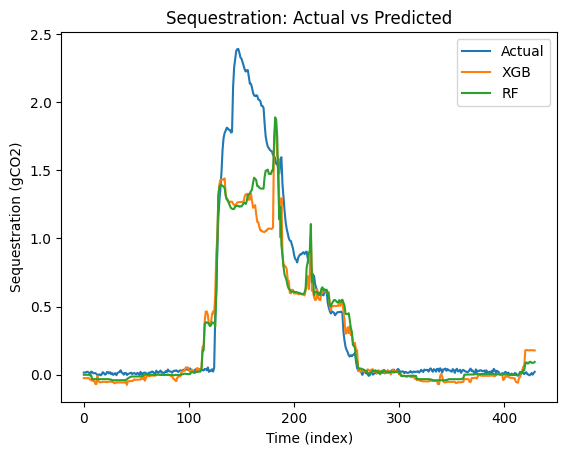

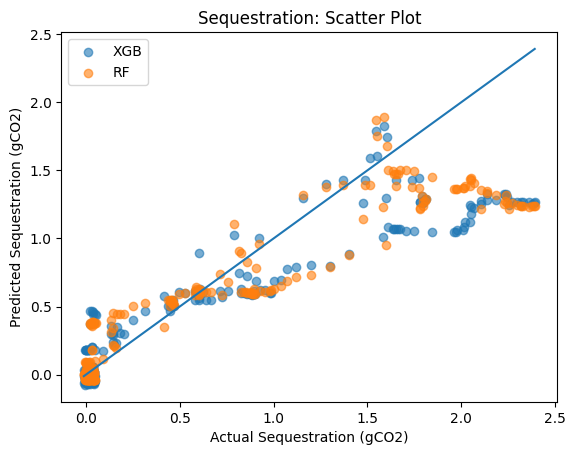

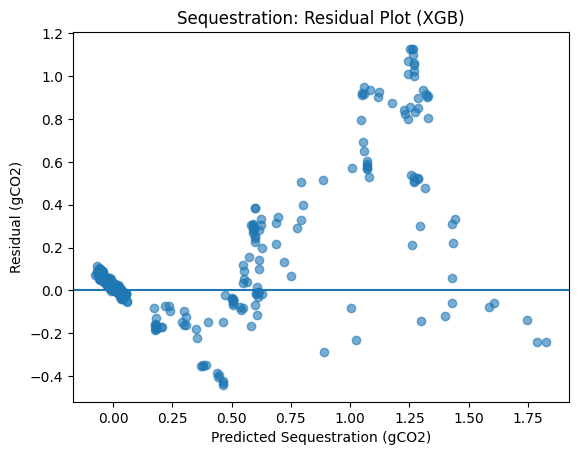

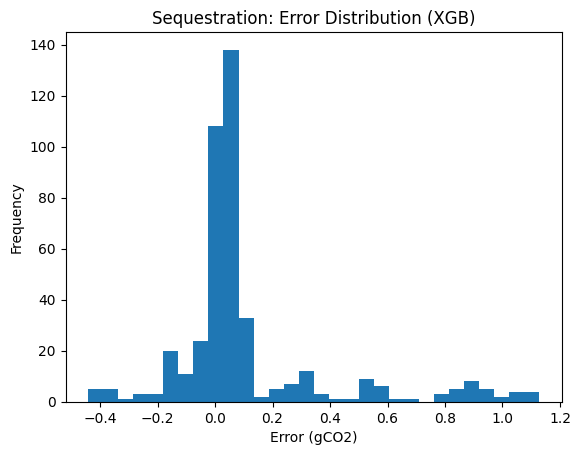

In [ ]:

# ---------- TIME SERIES ----------
plt.figure()
plt.plot(y_test.values, label="Actual")
plt.plot(pred_xgb_seq, label="XGB")
plt.plot(pred_rf_seq, label="RF")
plt.legend()
plt.title("Sequestration: Actual vs Predicted")
plt.xlabel("Time (index)")
plt.ylabel("Sequestration (gCO2)")
plt.show()


# ---------- SCATTER ----------
plt.figure()
plt.scatter(y_test, pred_xgb_seq, label="XGB", alpha=0.6)
plt.scatter(y_test, pred_rf_seq, label="RF", alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()])
plt.legend()
plt.title("Sequestration: Scatter Plot")
plt.xlabel("Actual Sequestration (gCO2)")
plt.ylabel("Predicted Sequestration (gCO2)")
plt.show()


# ---------- RESIDUAL ----------
res_seq = y_test - pred_xgb_seq

plt.figure()
plt.scatter(pred_xgb_seq, res_seq, alpha=0.6)
plt.axhline(0)
plt.title("Sequestration: Residual Plot (XGB)")
plt.xlabel("Predicted Sequestration (gCO2)")
plt.ylabel("Residual (gCO2)")
plt.show()


# ---------- ERROR DISTRIBUTION ----------
plt.figure()
plt.hist(res_seq, bins=30)
plt.title("Sequestration: Error Distribution (XGB)")
plt.xlabel("Error (gCO2)")
plt.ylabel("Frequency")
plt.show()

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GRU, Dense, Bidirectional
from sklearn.preprocessing import MinMaxScaler

In [ ]:
def create_sequences(X, y, window=12):
    Xs, ys = [], []
    for i in range(len(X)-window):
        Xs.append(X[i:i+window])
        ys.append(y[i+window])
    return np.array(Xs), np.array(ys)

In [ ]:
features = ['co2_proxy','lag1','lag3']

scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(df[features])

y = df['respiration_gCO2'].values

X_seq, y_seq = create_sequences(X_scaled, y, window=12)

split = int(len(X_seq)*0.8)

X_train_seq, X_test_seq = X_seq[:split], X_seq[split:]
y_train_seq, y_test_seq = y_seq[:split], y_seq[split:]

model = Sequential([
    Bidirectional(GRU(32)),
    Dense(1)
])

model.compile(optimizer='adam', loss='mse')

model.fit(X_train_seq, y_train_seq, epochs=10, verbose=1)

pred = model.predict(X_test_seq).flatten()

print("\n=== BiGRU RESPIRATION ===")
print("R2:", r2_score(y_test_seq, pred))
print("MAE:", mean_absolute_error(y_test_seq, pred))

Epoch 1/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - loss: 4.1478
Epoch 2/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.2819
Epoch 3/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.1748
Epoch 4/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.1245
Epoch 5/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.1007
Epoch 6/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0951
Epoch 7/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0945
Epoch 8/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0938
Epoch 9/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0930
Epoch 10/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0921
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step

=== BiGRU RESPIRATION ===
R2: 0.9103538466785551
MAE: 0.22757560028284424


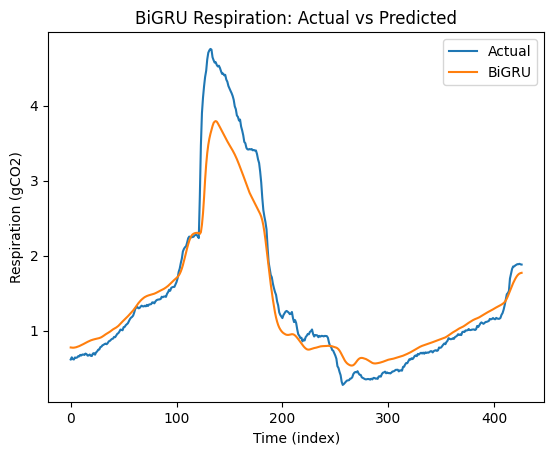

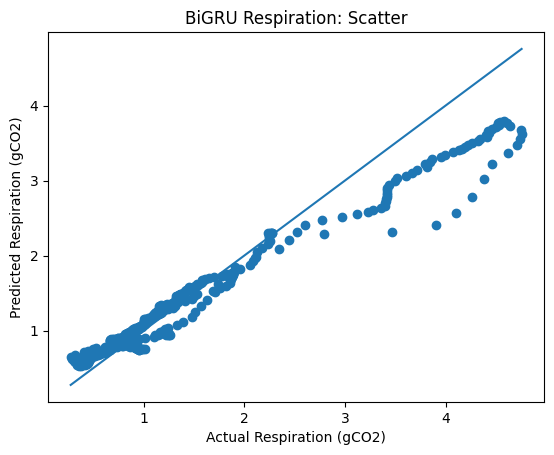

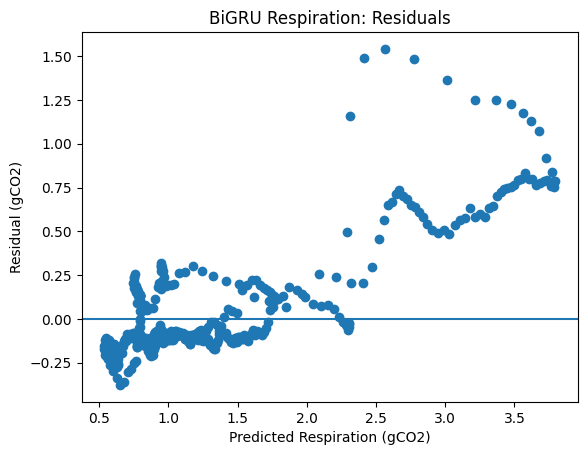

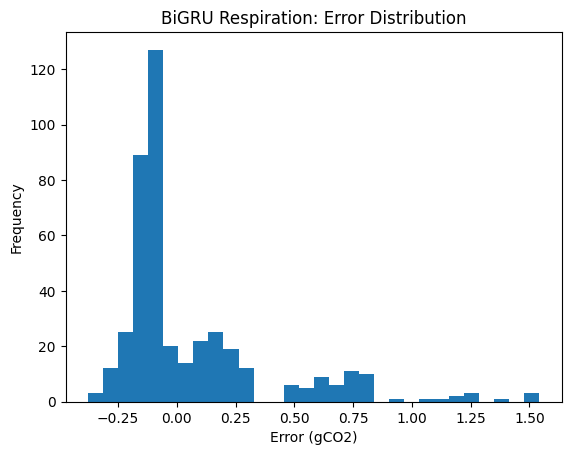

In [ ]:
# ---------- TIME SERIES ----------
plt.figure()
plt.plot(y_test_seq, label="Actual")
plt.plot(pred, label="BiGRU")
plt.legend()
plt.title("BiGRU Respiration: Actual vs Predicted")
plt.xlabel("Time (index)")
plt.ylabel("Respiration (gCO2)")
plt.show()


# ---------- SCATTER ----------
plt.figure()
plt.scatter(y_test_seq, pred)
plt.plot([y_test_seq.min(), y_test_seq.max()],
         [y_test_seq.min(), y_test_seq.max()])
plt.title("BiGRU Respiration: Scatter")
plt.xlabel("Actual Respiration (gCO2)")
plt.ylabel("Predicted Respiration (gCO2)")
plt.show()


# ---------- RESIDUAL ----------
res = y_test_seq - pred

plt.figure()
plt.scatter(pred, res)
plt.axhline(0)
plt.title("BiGRU Respiration: Residuals")
plt.xlabel("Predicted Respiration (gCO2)")
plt.ylabel("Residual (gCO2)")
plt.show()


# ---------- ERROR DISTRIBUTION ----------
plt.figure()
plt.hist(res, bins=30)
plt.title("BiGRU Respiration: Error Distribution")
plt.xlabel("Error (gCO2)")
plt.ylabel("Frequency")
plt.show()

In [ ]:
features = ['co2_proxy','co2_light','co2_light_lag']

scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(df[features])

y = df['sequestration_gCO2'].values

X_seq, y_seq = create_sequences(X_scaled, y, window=12)

split = int(len(X_seq)*0.8)

X_train_seq, X_test_seq = X_seq[:split], X_seq[split:]
y_train_seq, y_test_seq = y_seq[:split], y_seq[split:]

model = Sequential([
    Bidirectional(GRU(32)),
    Dense(1)
])

model.compile(optimizer='adam', loss='mse')

model.fit(X_train_seq, y_train_seq, epochs=10, verbose=1)

pred = model.predict(X_test_seq).flatten()

print("\n=== BiGRU SEQUESTRATION ===")
print("R2:", r2_score(y_test_seq, pred))
print("MAE:", mean_absolute_error(y_test_seq, pred))

Epoch 1/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - loss: 0.3800
Epoch 2/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.1229
Epoch 3/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0974
Epoch 4/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0732
Epoch 5/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0448
Epoch 6/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0373
Epoch 7/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0349
Epoch 8/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0316
Epoch 9/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0293
Epoch 10/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0286
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step

=== BiGRU SEQUESTRATION ===
R2: 0.9499843835858811
MAE: 0.0865747309798841


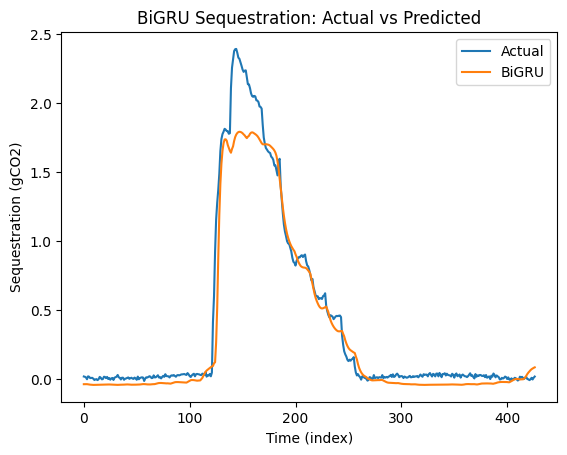

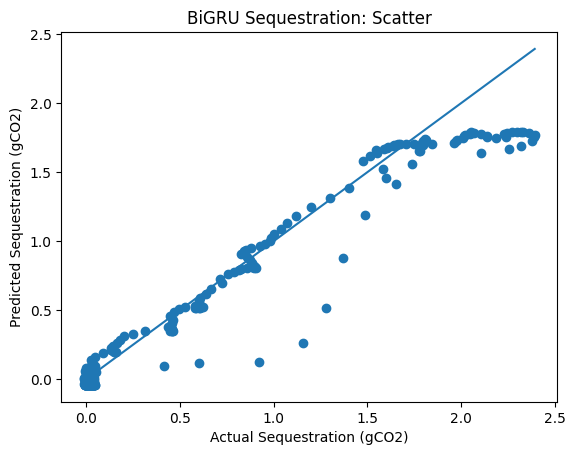

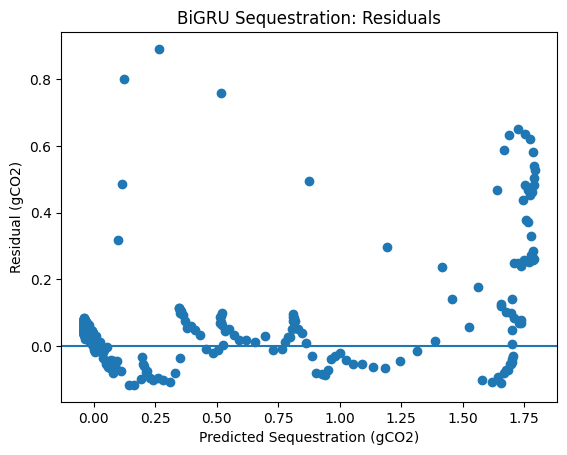

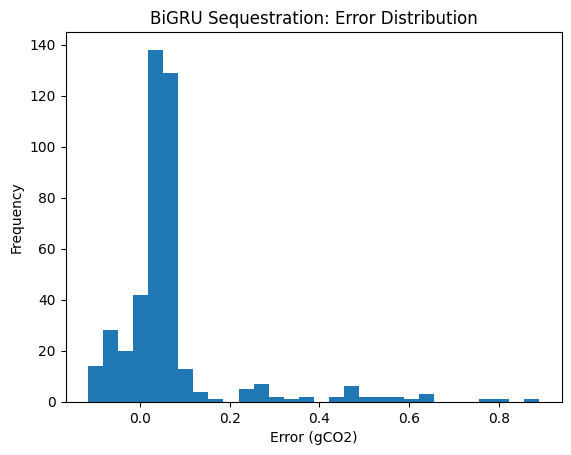

In [ ]:
# ---------- TIME SERIES ----------
plt.figure()
plt.plot(y_test_seq, label="Actual")
plt.plot(pred, label="BiGRU")
plt.legend()
plt.title("BiGRU Sequestration: Actual vs Predicted")
plt.xlabel("Time (index)")
plt.ylabel("Sequestration (gCO2)")
plt.show()


# ---------- SCATTER ----------
plt.figure()
plt.scatter(y_test_seq, pred)
plt.plot([y_test_seq.min(), y_test_seq.max()],
         [y_test_seq.min(), y_test_seq.max()])
plt.title("BiGRU Sequestration: Scatter")
plt.xlabel("Actual Sequestration (gCO2)")
plt.ylabel("Predicted Sequestration (gCO2)")
plt.show()


# ---------- RESIDUAL ----------
res = y_test_seq - pred

plt.figure()
plt.scatter(pred, res)
plt.axhline(0)
plt.title("BiGRU Sequestration: Residuals")
plt.xlabel("Predicted Sequestration (gCO2)")
plt.ylabel("Residual (gCO2)")
plt.show()


# ---------- ERROR DISTRIBUTION ----------
plt.figure()
plt.hist(res, bins=30)
plt.title("BiGRU Sequestration: Error Distribution")
plt.xlabel("Error (gCO2)")
plt.ylabel("Frequency")
plt.show()